# Cold–warm: CW mean & basin-warming plots

_Run `cw_calculations.ipynb` first. 20% ranges removed; dataframe-prep cells included so boxplots work._


In [34]:
# Load Packages
import numpy as np
import xarray as xr
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.transforms as transforms
import cartopy.crs as ccrs
import calendar, os, re
from matplotlib.lines import Line2D
import seaborn as sns
import pandas as pd
import matplotlib.gridspec as gridspec
from scipy.stats import norm, scoreatpercentile
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.patches as patches
from matplotlib.gridspec import GridSpec

%matplotlib inline


In [35]:
import sys, os
_p = os.getcwd()
for _ in range(6):
    if os.path.exists(os.path.join(_p, 'functions.py')):
        sys.path.insert(0, _p); break
    _p = os.path.dirname(_p)
from functions import *


In [36]:
# Load variables computed in cw_calculations.ipynb
load_state(globals())


[load_state] loaded 215 variables from /Users/isabelaconde/Documents/GitHub/JRA55-do_ctrl_ERA5-forcings/processed_data/state.pkl
[load_state] available: DA_all, In, Out, STATE_DIR, STATE_FILE, all_trend_percentiles, ax, basin_cmip, basin_era5, basin_jra55, basin_noaa, basin_omip ...


{'In': ['',
  "# Load Packages\nimport numpy as np\nimport xarray as xr\nimport matplotlib\nimport matplotlib.pyplot as plt\nimport matplotlib.transforms as transforms\nimport cartopy.crs as ccrs\nimport calendar, os, re, datetime\nfrom datetime import datetime as _dt\nfrom pathlib import Path\nfrom matplotlib.lines import Line2D\nimport seaborn as sns\nimport pandas as pd\nimport matplotlib.gridspec as gridspec\nfrom scipy.stats import norm, scoreatpercentile\nfrom mpl_toolkits.axes_grid1 import make_axes_locatable\nimport matplotlib.patches as patches\nfrom matplotlib.gridspec import GridSpec\nfrom xhistogram.xarray import histogram\n\nget_ipython().run_line_magic('matplotlib', 'inline')",
  "import sys, os\n_p = os.getcwd()\nfor _ in range(6):\n    if os.path.exists(os.path.join(_p, 'functions.py')):\n        sys.path.insert(0, _p); break\n    _p = os.path.dirname(_p)\nfrom functions import *  # shared helper functions",
  "def quantiles_xhist(data):\n    hist_T = data.sel(lon = sli

# cold-warm grad trend

/var/folders/3m/hb6030nd3ml4fk_t3lq08f4w0000gn/T/ipykernel_53114/2479239599.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_all, x="group", y="value", inner=None, ax=ax, palette={"CMIP": "sandybrown", "OMIP": "steelblue"}, alpha=0.3 )
/var/folders/3m/hb6030nd3ml4fk_t3lq08f4w0000gn/T/ipykernel_53114/2479239599.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(data=df_means, x="group", y="value", ax=ax, marker="o", size=9, palette={"CMIP": "sandybrown", "OMIP": "steelblue"})


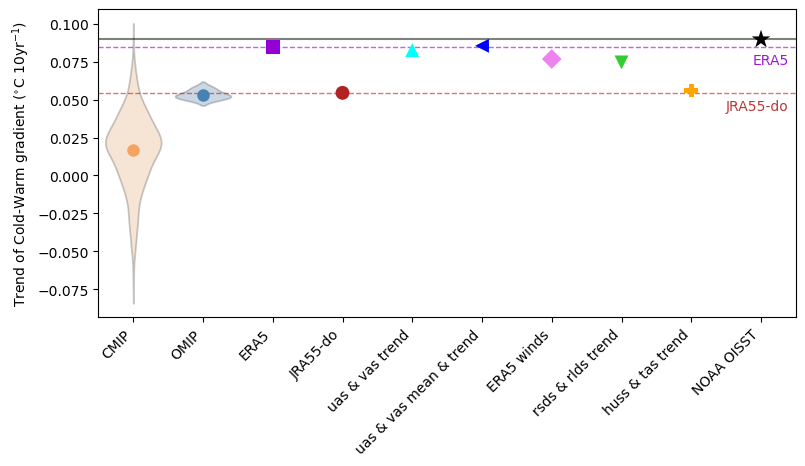

In [57]:

sources = ['ERA5 forced','JRA55-do forced','JRA55-do forced with ERA5 uas, vas trend','JRA55-do forced with ERA5 uas, vas trend and mean state','JRA55-do forced with ERA5 uas, vas', 'JRA55-do forced with ERA5 rsds, rlds trend','JRA55-do forced with ERA5 huss, tas trend','NOAA OISST']
colors  = ['darkviolet', 'firebrick', 'cyan','b', 'violet', 'limegreen', 'orange', 'k']

obs_perturb_df = pd.DataFrame({
    'Source': ['ERA5','JRA55-do','uas & vas trend','uas & vas mean & trend','ERA5 winds', 'rsds & rlds trend','huss & tas trend','NOAA OISST'],
    'values': np.array([cw_era5.values,cw_jra55.values,cw_perturb_uas_vas.values,cw_perturb_winds_mean_trend.values,cw_perturb_winds.values, cw_perturb_rsds_rlds.values,
                        cw_perturb_huss_tas.values,  cw_noaa.values])*10*12
})

obs_perturb_df = obs_perturb_df.rename(columns={"values": "value"})
obs_perturb_df["group"] = obs_perturb_df["Source"]

order = list(obs_perturb_df["group"].unique())
pal = dict(zip(order, colors[:len(order)]))

noaa = obs_perturb_df["group"].eq("NOAA OISST")
import matplotlib.transforms as transforms

# markers = ['o', 's', '^',  '<','D','v', 'P', 'X', '*']  # last one is NOAA
# colors  = ['darkviolet', 'firebrick', 'cyan', 'b', 'violet','r', 'limegreen', 'orange',  'red', 'k']

fig, ax = plt.subplots(figsize=(9, 4))
trans = transforms.blended_transform_factory(ax.transAxes, ax.transData)

sns.violinplot(data=df_all, x="group", y="value", inner=None, ax=ax, palette={"CMIP": "sandybrown", "OMIP": "steelblue"}, alpha=0.3 )
sns.stripplot(data=df_means, x="group", y="value", ax=ax, marker="o", size=9, palette={"CMIP": "sandybrown", "OMIP": "steelblue"})

# NOAA reference line
ax.axhline(y=float(cw_noaa.values) * 10 * 12, color='k', linestyle='-', linewidth=1.5, alpha=0.5, label='_nolegend_')

# --- obs/perturb points: one per Source, with per-source marker (NOAA gets '*') ---
obs_perturb_df = obs_perturb_df.rename(columns={"values": "value"})  # if needed
obs_perturb_df["group"] = obs_perturb_df["Source"]

# ensure consistent x ordering for these points
srcs = list(obs_perturb_df["group"].unique())
order2 = order if "order" in globals() and order is not None else srcs

# map source -> (marker, color) with NOAA last
non_noaa_sources = [s for s in order2 if s in srcs and s != "NOAA OISST"]
noaa_source = "NOAA OISST" if "NOAA OISST" in srcs else None

marker_map = {}
color_map  = {}

# assign markers/colors to non-NOAA (cycled if needed)
for i, s in enumerate(non_noaa_sources):
    marker_map[s] = markers[i % (len(markers) - 1)]   # exclude last ('*')
    color_map[s]  = colors[i % (len(colors) - 1)]     # exclude last ('k') if you want NOAA black

# NOAA marker + colour
if noaa_source is not None:
    marker_map[noaa_source] = markers[-1]   # '*'
    color_map[noaa_source]  = colors[-1]    # 'k'

# plot each source separately so we can control marker per point
for s in non_noaa_sources + ([noaa_source] if noaa_source is not None else []):
    if s is None:
        continue
    sub = obs_perturb_df.loc[obs_perturb_df["group"] == s]
    sns.stripplot(
        data=sub, x="group", y="value", ax=ax,
        order=order2,
        marker=marker_map[s],
        size=(14 if marker_map[s] == "*" else 10),
        color=color_map[s],
        edgecolor="none", linewidth=0.5
    )

# ERA5 + JRA55-do line labels
dy = 0.02 * (ax.get_ylim()[1] - ax.get_ylim()[0])
for src in ["ERA5", "JRA55-do"]:
    if (obs_perturb_df["group"] == src).any() and src in pal:
        y = float(obs_perturb_df.loc[obs_perturb_df["group"] == src, "value"].iloc[0])
        ax.axhline(y=y, color=pal[src], linestyle="--", linewidth=1, alpha=0.6, label="_nolegend_")
        ax.text(0.99, y - dy, src, transform=trans, ha="right", va="top",
                color=pal[src], alpha=0.9)

plt.xlabel('')
plt.ylabel(r'Trend of Cold-Warm gradient ($^{\circ}$C 10yr$^{-1}$)')
plt.xticks(rotation=45, ha="right")

plt.show()
outpath = "/Users/isabelaconde/Desktop/cw_1982-2017.pdf"
fig.savefig(outpath, format="pdf", bbox_inches="tight")

# cw mean

In [37]:
cw_mean_cmip = xr.open_dataarray('/Users/isabelaconde/Desktop/data/cw_mean.nc').load()
# cw_mean

In [38]:
folder = "/Users/isabelaconde/Desktop/data/exp_percentiles"

for fname in os.listdir(folder):
    if fname.endswith(".nc"):
        var_name = os.path.splitext(fname)[0]
        globals()[var_name] = xr.open_dataarray(os.path.join(folder, fname))
        print(f"Loaded {var_name}")


Loaded jra55_percentiles
Loaded uas_vas_mean_trend_percentiles
Loaded all_trend_percentiles
Loaded cold_mean
Loaded rsds_rlds_trend_percentiles
Loaded huss_tas_trend_percentiles
Loaded era5_percentiles
Loaded era5_winds_percentiles
Loaded warm_mean
Loaded uas_vas_trend_percentiles


In [39]:
jra55_mean_cw = (jra55_percentiles.sel(area = slice(0.5,1)).mean(dim="area") - jra55_percentiles.sel(area = slice(0,0.5)).mean(dim="area")).mean(dim = 'time')
era5_mean_cw = (era5_percentiles.sel(area = slice(0.5,1)).mean(dim="area") - era5_percentiles.sel(area = slice(0,0.5)).mean(dim="area")).mean(dim = 'time')
uas_vas_mean_trend_mean_cw = (uas_vas_mean_trend_percentiles.sel(area = slice(0.5,1)).mean(dim="area") - uas_vas_mean_trend_percentiles.sel(area = slice(0,0.5)).mean(dim="area")).mean(dim = 'time')
rsds_rlds_trend_mean_cw = (rsds_rlds_trend_percentiles.sel(area = slice(0.5,1)).mean(dim="area") - rsds_rlds_trend_percentiles.sel(area = slice(0,0.5)).mean(dim="area")).mean(dim = 'time')
huss_tas_trend_mean_cw = (huss_tas_trend_percentiles.sel(area = slice(0.5,1)).mean(dim="area") - huss_tas_trend_percentiles.sel(area = slice(0,0.5)).mean(dim="area")).mean(dim = 'time')
era5_winds_mean_cw = (era5_winds_percentiles.sel(area = slice(0.5,1)).mean(dim="area") - era5_winds_percentiles.sel(area = slice(0,0.5)).mean(dim="area")).mean(dim = 'time')
uas_vas_trend_mean_cw = (uas_vas_trend_percentiles.sel(area = slice(0.5,1)).mean(dim="area") - uas_vas_trend_percentiles.sel(area = slice(0,0.5)).mean(dim="area")).mean(dim = 'time')


In [53]:
noaa_mean_cw = (noaa_sst_percentiles.sel(area = slice(0.5,1)).mean(dim="area") - noaa_sst_percentiles.sel(area = slice(0,0.5)).mean(dim="area")).mean(dim = 'time')



In [54]:
# omip_models
# cw_omip
# lo = cw_mean.quantile(0.1, dim="ensem")
# hi = cw_mean.quantile(0.9, dim="run")

# cw_cmip_trim = cw_cmip #.where((cw_cmip >= lo) & (cw_cmip <= hi), drop=True)

df_cw_mean_cmip = (cw_mean_cmip).to_dataframe(name="value").reset_index()
df_cw_mean_cmip["group"] = "CMIP"


vals = [float(v.values) for v in cw_mean_omip.values()]   
df_mean_omip = pd.DataFrame({"value": vals})
df_mean_omip["group"] = "OMIP"

df_mean_all = pd.concat([df_cw_mean_cmip[["value","group"]], df_mean_omip], ignore_index=True)

/var/folders/3m/hb6030nd3ml4fk_t3lq08f4w0000gn/T/ipykernel_53114/2025860411.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_mean_all, x="group", y="value", inner=None, ax=ax, palette={"CMIP": "sandybrown", "OMIP": "steelblue"}, alpha=0.3 )
/var/folders/3m/hb6030nd3ml4fk_t3lq08f4w0000gn/T/ipykernel_53114/2025860411.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(


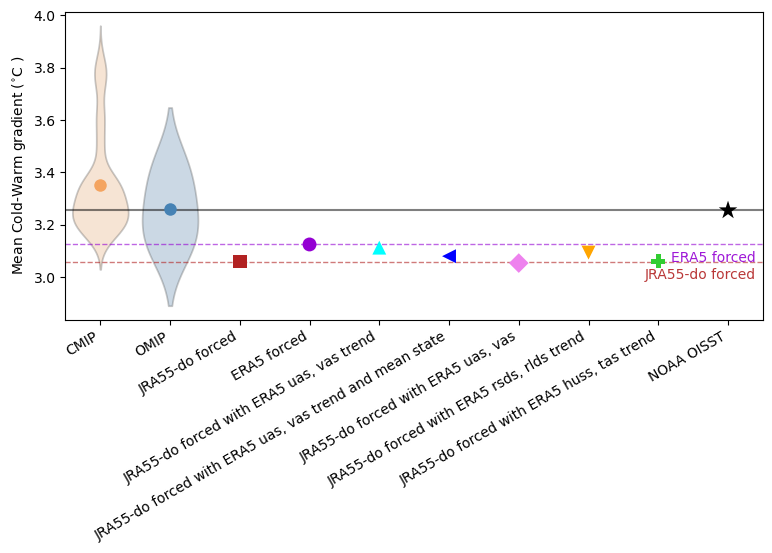

In [55]:

sources = ['JRA55-do forced','ERA5 forced','JRA55-do forced with ERA5 uas, vas trend','JRA55-do forced with ERA5 uas, vas trend and mean state','JRA55-do forced with ERA5 uas, vas', 'JRA55-do forced with ERA5 rsds, rlds trend','JRA55-do forced with ERA5 huss, tas trend','NOAA OISST']
colors  = [ 'firebrick','darkviolet', 'cyan','b', 'violet', 'orange','limegreen', 'k']

obs_perturb_mean_df = pd.DataFrame({
    'Source': ['JRA55-do forced','ERA5 forced','JRA55-do forced with ERA5 uas, vas trend','JRA55-do forced with ERA5 uas, vas trend and mean state','JRA55-do forced with ERA5 uas, vas', 'JRA55-do forced with ERA5 rsds, rlds trend','JRA55-do forced with ERA5 huss, tas trend','NOAA OISST'],
    'values': np.array([jra55_mean_cw.values,era5_mean_cw.values,uas_vas_trend_mean_cw.values,uas_vas_mean_trend_mean_cw.values,era5_winds_mean_cw.values, rsds_rlds_trend_mean_cw.values,
                        huss_tas_trend_mean_cw.values,  noaa_mean_cw.values])
})

obs_perturb_mean_df = obs_perturb_mean_df.rename(columns={"values": "value"})
obs_perturb_mean_df["group"] = obs_perturb_mean_df["Source"]

order = list(obs_perturb_mean_df["group"].unique())
pal = dict(zip(order, colors[:len(order)]))

noaa = obs_perturb_mean_df["group"].eq("NOAA OISST")

markers = ['s','o',  '^',  '<','D','v', 'P',  '*']  # last one is NOAA
# colors  = ['darkviolet', 'firebrick', 'cyan', 'b', 'violet','r', 'limegreen',  'orange', 'k']

fig, ax = plt.subplots(figsize=(9, 4))
trans = transforms.blended_transform_factory(ax.transAxes, ax.transData)

sns.violinplot(data=df_mean_all, x="group", y="value", inner=None, ax=ax, palette={"CMIP": "sandybrown", "OMIP": "steelblue"}, alpha=0.3 )
df_mean = df_mean_all.groupby("group", as_index=False)["value"].mean()

sns.stripplot(
    data=df_mean,
    x="group",
    y="value",
    ax=ax,
    marker="o",
    size=9,
    palette={"CMIP": "sandybrown", "OMIP": "steelblue"}
)
# sns.stripplot(
#     data=df_mean_all,
#     x="group",
#     y="value",
#     ax=ax,
#     palette={"CMIP": "sandybrown", "OMIP": "steelblue"},
#     alpha=0.3,
#     jitter=0.25,
#     size=6
# )
# NOAA reference line
ax.axhline(y=float(noaa_mean_cw.values) , color='k', linestyle='-', linewidth=1.5, alpha=0.5, label='_nolegend_')

# --- obs/perturb points: one per Source, with per-source marker (NOAA gets '*') ---
obs_perturb_mean_df = obs_perturb_mean_df.rename(columns={"values": "value"})  # if needed
obs_perturb_mean_df["group"] = obs_perturb_mean_df["Source"]

# ensure consistent x ordering for these points
srcs = list(obs_perturb_mean_df["group"].unique())
order2 = order if "order" in globals() and order is not None else srcs

# map source -> (marker, color) with NOAA last
non_noaa_sources = [s for s in order2 if s in srcs and s != "NOAA OISST"]
noaa_source = "NOAA OISST" if "NOAA OISST" in srcs else None

marker_map = {}
color_map  = {}

# assign markers/colors to non-NOAA (cycled if needed)
for i, s in enumerate(non_noaa_sources):
    marker_map[s] = markers[i % (len(markers) - 1)]   # exclude last ('*')
    color_map[s]  = colors[i % (len(colors) - 1)]     # exclude last ('k') if you want NOAA black

# NOAA marker + colour
if noaa_source is not None:
    marker_map[noaa_source] = markers[-1]   # '*'
    color_map[noaa_source]  = colors[-1]    # 'k'

# plot each source separately so we can control marker per point
for s in non_noaa_sources + ([noaa_source] if noaa_source is not None else []):
    if s is None:
        continue
    sub = obs_perturb_mean_df.loc[obs_perturb_mean_df["group"] == s]
    sns.stripplot(
        data=sub, x="group", y="value", ax=ax,
        order=order2,
        marker=marker_map[s],
        size=(14 if marker_map[s] == "*" else 10),
        color=color_map[s],
        edgecolor="none", linewidth=0.5
    )

# ERA5 + JRA55-do line labels
dy = 0.02 * (ax.get_ylim()[1] - ax.get_ylim()[0])
for src in ["ERA5 forced", "JRA55-do forced"]:
    if (obs_perturb_mean_df["group"] == src).any() and src in pal:
        y = float(obs_perturb_mean_df.loc[obs_perturb_mean_df["group"] == src, "value"].iloc[0])
        ax.axhline(y=y, color=pal[src], linestyle="--", linewidth=1, alpha=0.6, label="_nolegend_")
        ax.text(0.99, y - dy, src, transform=trans, ha="right", va="top",
                color=pal[src], alpha=0.9)

plt.xlabel('')
plt.ylabel(r'Mean Cold-Warm gradient ($^{\circ}$C )')
plt.xticks(rotation=30, ha="right")

plt.show()
outpath = "/Users/isabelaconde/Desktop/cw_1982-2017.pdf"
fig.savefig(outpath, format="pdf", bbox_inches="tight")

# basin warming

In [44]:
# warmest 50% mean only
basin_omip = {}
for da in mod_labs:
    basin_omip[da] = percentiles_omip_trend[da].sel(area=slice(0, 1)).mean(dim="area")*10*12
print("omip calculated")

basin_cmip = DA_all.sel(area=slice(0, 1)).mean(dim="area")*10*12
print("cmip calculated")

basin_noaa = noaa_sst_trend.sel(area=slice(0, 1)).mean(dim="area")*10*12
print("noaa calculated")

basin_jra55 = control_percent_trend.sel(area=slice(0, 1)).mean(dim="area")*10*12
basin_era5  = era5_percent_trend.sel(area=slice(0, 1)).mean(dim="area")*10*12

basin_perturb_uas_vas   = perturb_percent_era5_uas_vas_trend.sel(area=slice(0, 1)).mean(dim="area")*10*12
basin_perturb_huss_tas  = perturb_percent_era5_huss_tas_trend.sel(area=slice(0, 1)).mean(dim="area")*10*12
basin_perturb_rsds_rlds = perturb_percent_era5_rsds_rlds_trend.sel(area=slice(0, 1)).mean(dim="area")*10*12
basin_perturb_winds     = perturb_percent_era5_winds.sel(area=slice(0, 1)).mean(dim="area")*10*12
basin_perturb_all       = perturb_percent_all_trend.sel(area=slice(0, 1)).mean(dim="area")*10*12
# warm50_cm2 = cm2_percent_trend.sel(area=slice(0.5, 1)).mean(dim="area")
basin_perturb_winds_mean_trend = perturb_percent_winds_mean_trend.sel(area=slice(0, 1)).mean(dim="area")*10*12
print("perturbation calculated")


omip calculated
cmip calculated
noaa calculated
perturbation calculated


In [45]:
df_basin_cmip = (basin_cmip).to_dataframe(name="value").reset_index()
df_basin_cmip["group"] = "CMIP"


vals = [float(v.values) for v in basin_omip.values()]   
df_basin_omip = pd.DataFrame({"value": vals})
df_basin_omip["group"] = "OMIP"

df_basin_all = pd.concat([df_basin_cmip[["value","group"]], df_basin_omip], ignore_index=True)

/var/folders/3m/hb6030nd3ml4fk_t3lq08f4w0000gn/T/ipykernel_53114/4272795448.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_basin_all, x="group", y="value", inner=None, ax=ax, palette={"CMIP": "sandybrown", "OMIP": "steelblue"}, alpha=0.3 )
/var/folders/3m/hb6030nd3ml4fk_t3lq08f4w0000gn/T/ipykernel_53114/4272795448.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(


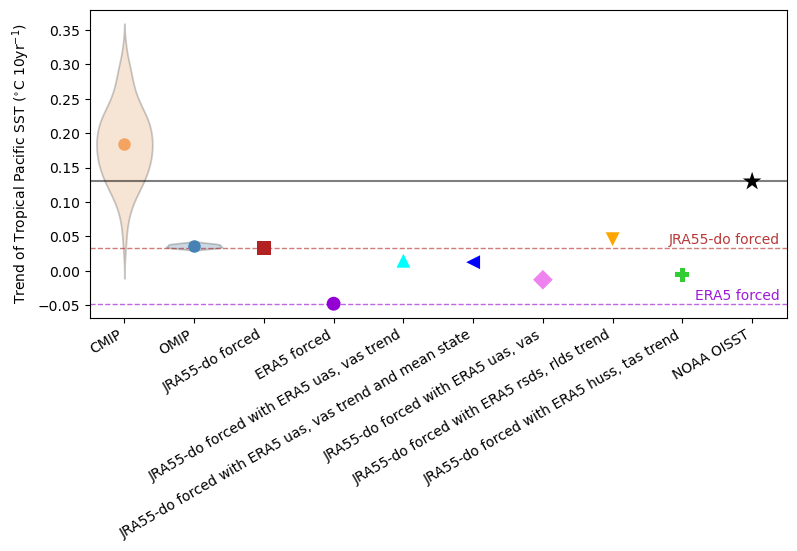

In [52]:

sources = ['JRA55-do forced','ERA5 forced','JRA55-do forced with ERA5 uas, vas trend','JRA55-do forced with ERA5 uas, vas trend and mean state','JRA55-do forced with ERA5 uas, vas', 'JRA55-do forced with ERA5 rsds, rlds trend','JRA55-do forced with ERA5 huss, tas trend','NOAA OISST']
colors  = [ 'firebrick','darkviolet', 'cyan','b', 'violet', 'orange','limegreen', 'k']

obs_perturb_basin_df = pd.DataFrame({
    'Source': ['JRA55-do forced','ERA5 forced','JRA55-do forced with ERA5 uas, vas trend','JRA55-do forced with ERA5 uas, vas trend and mean state','JRA55-do forced with ERA5 uas, vas', 'JRA55-do forced with ERA5 rsds, rlds trend','JRA55-do forced with ERA5 huss, tas trend','NOAA OISST'],
    'values': np.array([basin_jra55.values,basin_era5.values,basin_perturb_uas_vas.values,basin_perturb_winds_mean_trend.values,basin_perturb_winds.values, basin_perturb_rsds_rlds.values,
                        basin_perturb_huss_tas.values,  basin_noaa.values])
})

obs_perturb_basin_df = obs_perturb_basin_df.rename(columns={"values": "value"})
obs_perturb_basin_df["group"] = obs_perturb_basin_df["Source"]

order = list(obs_perturb_basin_df["group"].unique())
pal = dict(zip(order, colors[:len(order)]))

noaa = obs_perturb_basin_df["group"].eq("NOAA OISST")

markers = ['s','o',  '^',  '<','D','v', 'P',  '*']  # last one is NOAA
# colors  = ['darkviolet', 'firebrick', 'cyan', 'b', 'violet','r', 'limegreen',  'orange', 'k']

fig, ax = plt.subplots(figsize=(9, 4))
trans = transforms.blended_transform_factory(ax.transAxes, ax.transData)

sns.violinplot(data=df_basin_all, x="group", y="value", inner=None, ax=ax, palette={"CMIP": "sandybrown", "OMIP": "steelblue"}, alpha=0.3 )
df_mean = df_basin_all.groupby("group", as_index=False)["value"].mean()

sns.stripplot(
    data=df_mean,
    x="group",
    y="value",
    ax=ax,
    marker="o",
    size=9,
    palette={"CMIP": "sandybrown", "OMIP": "steelblue"}
)

# NOAA reference line
ax.axhline(y=float(basin_noaa.values) , color='k', linestyle='-', linewidth=1.5, alpha=0.5, label='_nolegend_')

# --- obs/perturb points: one per Source, with per-source marker (NOAA gets '*') ---
obs_perturb_basin_df = obs_perturb_basin_df.rename(columns={"values": "value"})  # if needed
obs_perturb_basin_df["group"] = obs_perturb_basin_df["Source"]

# ensure consistent x ordering for these points
srcs = list(obs_perturb_basin_df["group"].unique())
order2 = order if "order" in globals() and order is not None else srcs

# map source -> (marker, color) with NOAA last
non_noaa_sources = [s for s in order2 if s in srcs and s != "NOAA OISST"]
noaa_source = "NOAA OISST" if "NOAA OISST" in srcs else None

marker_map = {}
color_map  = {}

# assign markers/colors to non-NOAA (cycled if needed)
for i, s in enumerate(non_noaa_sources):
    marker_map[s] = markers[i % (len(markers) - 1)]   # exclude last ('*')
    color_map[s]  = colors[i % (len(colors) - 1)]     # exclude last ('k') if you want NOAA black

# NOAA marker + colour
if noaa_source is not None:
    marker_map[noaa_source] = markers[-1]   # '*'
    color_map[noaa_source]  = colors[-1]    # 'k'

# plot each source separately so we can control marker per point
for s in non_noaa_sources + ([noaa_source] if noaa_source is not None else []):
    if s is None:
        continue
    sub = obs_perturb_basin_df.loc[obs_perturb_basin_df["group"] == s]
    sns.stripplot(
        data=sub, x="group", y="value", ax=ax,
        order=order2,
        marker=marker_map[s],
        size=(14 if marker_map[s] == "*" else 10),
        color=color_map[s],
        edgecolor="none", linewidth=0.5
    )

# ERA5 + JRA55-do line labels
dy = 0.05 * (ax.get_ylim()[1] - ax.get_ylim()[0])
for src in ["ERA5 forced", "JRA55-do forced"]:
    if (obs_perturb_basin_df["group"] == src).any() and src in pal:
        y = float(obs_perturb_basin_df.loc[obs_perturb_basin_df["group"] == src, "value"].iloc[0])
        ax.axhline(y=y, color=pal[src], linestyle="--", linewidth=1, alpha=0.6, label="_nolegend_")
        ax.text(0.99, y + dy, src, transform=trans, ha="right", va="top",
                color=pal[src], alpha=0.9)

plt.xlabel('')
plt.ylabel(r'Trend of Tropical Pacific SST ($^{\circ}$C 10yr$^{-1}$)')
plt.xticks(rotation=30, ha="right")

plt.show()
outpath = "/Users/isabelaconde/Desktop/trop_pa_1982-2017.pdf"
fig.savefig(outpath, format="pdf", bbox_inches="tight")

# All three - for paper

/var/folders/3m/hb6030nd3ml4fk_t3lq08f4w0000gn/T/ipykernel_53114/2584997154.py:101: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/var/folders/3m/hb6030nd3ml4fk_t3lq08f4w0000gn/T/ipykernel_53114/2584997154.py:110: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(
/var/folders/3m/hb6030nd3ml4fk_t3lq08f4w0000gn/T/ipykernel_53114/2584997154.py:145: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/var/folders/3m/hb6030nd3ml4fk_t3lq08f4w0000gn/T/ipykernel_53114/2584997154.py:154: FutureWarning: 

Passing `palette` without assigning `hue` is 

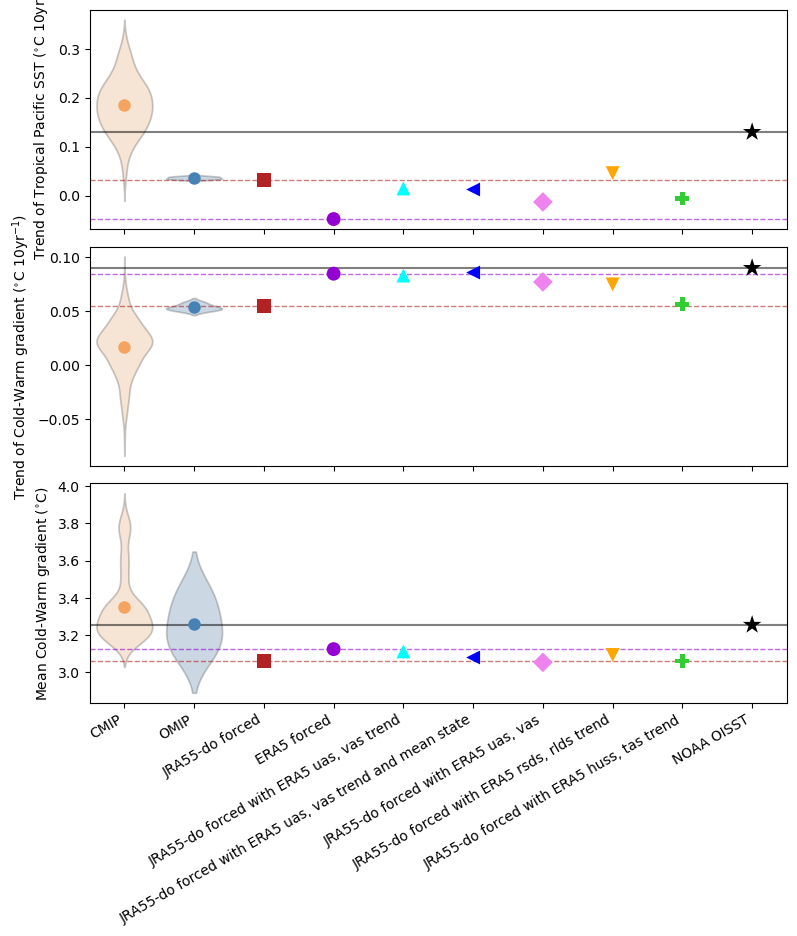

In [59]:
sources = [
    'JRA55-do forced',
    'ERA5 forced',
    'JRA55-do forced with ERA5 uas, vas trend',
    'JRA55-do forced with ERA5 uas, vas trend and mean state',
    'JRA55-do forced with ERA5 uas, vas',
    'JRA55-do forced with ERA5 rsds, rlds trend',
    'JRA55-do forced with ERA5 huss, tas trend',
    'NOAA OISST'
]

colors = ['firebrick', 'darkviolet', 'cyan', 'b', 'violet', 'orange', 'limegreen', 'k']
markers = ['s', 'o', '^', '<', 'D', 'v', 'P', '*']   # NOAA = *

order = sources
pal = dict(zip(order, colors))

# -------------------------
# Tropical Pacific SST trend dataframe
# -------------------------
obs_perturb_basin_df = pd.DataFrame({
    'Source': sources,
    'value': np.array([
        basin_jra55.values,
        basin_era5.values,
        basin_perturb_uas_vas.values,
        basin_perturb_winds_mean_trend.values,
        basin_perturb_winds.values,
        basin_perturb_rsds_rlds.values,
        basin_perturb_huss_tas.values,
        basin_noaa.values
    ])
})
obs_perturb_basin_df["group"] = obs_perturb_basin_df["Source"]

# -------------------------
# Cold-warm trend dataframe
# -------------------------
obs_perturb_df = pd.DataFrame({
    'Source': sources,
    'value': np.array([
        cw_jra55.values,
        cw_era5.values,
        cw_perturb_uas_vas.values,
        cw_perturb_winds_mean_trend.values,
        cw_perturb_winds.values,
        cw_perturb_rsds_rlds.values,
        cw_perturb_huss_tas.values,
        cw_noaa.values
    ]) * 10 * 12
})
obs_perturb_df["group"] = obs_perturb_df["Source"]

# -------------------------
# Cold-warm mean dataframe
# -------------------------
obs_perturb_mean_df = pd.DataFrame({
    'Source': sources,
    'value': np.array([
        jra55_mean_cw.values,
        era5_mean_cw.values,
        uas_vas_trend_mean_cw.values,
        uas_vas_mean_trend_mean_cw.values,
        era5_winds_mean_cw.values,
        rsds_rlds_trend_mean_cw.values,
        huss_tas_trend_mean_cw.values,
        noaa_mean_cw.values
    ])
})
obs_perturb_mean_df["group"] = obs_perturb_mean_df["Source"]

# -------------------------
# marker / colour maps
# -------------------------
non_noaa_sources = [s for s in order if s != "NOAA OISST"]
noaa_source = "NOAA OISST"

marker_map = {}
color_map = {}

for i, s in enumerate(non_noaa_sources):
    marker_map[s] = markers[i]
    color_map[s] = colors[i]

marker_map[noaa_source] = markers[-1]
color_map[noaa_source] = colors[-1]

# -------------------------
# Plot
# -------------------------
fig, axes = plt.subplots(
    nrows=3, ncols=1, figsize=(9, 9), sharex=True,
    gridspec_kw={"hspace": 0.08}
)

ax1, ax2, ax3 = axes

# =====================================================
# Panel 1: Trend of tropical Pacific SST
# =====================================================
sns.violinplot(
    data=df_basin_all, x="group", y="value",
    inner=None, ax=ax1,
    palette={"CMIP": "sandybrown", "OMIP": "steelblue"},
    alpha=0.3
)

df_basin_mean = df_basin_all.groupby("group", as_index=False)["value"].mean()

sns.stripplot(
    data=df_basin_mean,
    x="group", y="value",
    ax=ax1,
    marker="o", size=9,
    palette={"CMIP": "sandybrown", "OMIP": "steelblue"}
)

ax1.axhline(
    y=float(basin_noaa.values),
    color='k', linestyle='-', linewidth=1.5, alpha=0.5, label='_nolegend_'
)

for s in order:
    sub = obs_perturb_basin_df.loc[obs_perturb_basin_df["group"] == s]
    sns.stripplot(
        data=sub, x="group", y="value", ax=ax1,
        order=order,
        marker=marker_map[s],
        size=(14 if marker_map[s] == "*" else 10),
        color=color_map[s],
        edgecolor="none", linewidth=0.5
    )

for src in ["ERA5 forced", "JRA55-do forced"]:
    y = float(obs_perturb_basin_df.loc[obs_perturb_basin_df["group"] == src, "value"].iloc[0])
    ax1.axhline(y=y, color=pal[src], linestyle="--", linewidth=1, alpha=0.6, label="_nolegend_")

ax1.set_xlabel('')
ax1.set_ylabel(r'Trend of Tropical Pacific SST ($^{\circ}$C 10yr$^{-1}$)')
ax1.tick_params(axis='x', labelbottom=False)

# =====================================================
# Panel 2: Trend of cold-warm gradient
# =====================================================
sns.violinplot(
    data=df_all, x="group", y="value",
    inner=None, ax=ax2,
    palette={"CMIP": "sandybrown", "OMIP": "steelblue"},
    alpha=0.3
)

df_trend_mean = df_all.groupby("group", as_index=False)["value"].mean()

sns.stripplot(
    data=df_trend_mean,
    x="group", y="value",
    ax=ax2,
    marker="o", size=9,
    palette={"CMIP": "sandybrown", "OMIP": "steelblue"}
)

ax2.axhline(
    y=float(cw_noaa.values) * 10 * 12,
    color='k', linestyle='-', linewidth=1.5, alpha=0.5, label='_nolegend_'
)

for s in order:
    sub = obs_perturb_df.loc[obs_perturb_df["group"] == s]
    sns.stripplot(
        data=sub, x="group", y="value", ax=ax2,
        order=order,
        marker=marker_map[s],
        size=(14 if marker_map[s] == "*" else 10),
        color=color_map[s],
        edgecolor="none", linewidth=0.5
    )

for src in ["ERA5 forced", "JRA55-do forced"]:
    y = float(obs_perturb_df.loc[obs_perturb_df["group"] == src, "value"].iloc[0])
    ax2.axhline(y=y, color=pal[src], linestyle="--", linewidth=1, alpha=0.6, label="_nolegend_")

ax2.set_xlabel('')
ax2.set_ylabel(r'Trend of Cold-Warm gradient ($^{\circ}$C 10yr$^{-1}$)')
ax2.tick_params(axis='x', labelbottom=False)

# =====================================================
# Panel 3: Mean cold-warm gradient
# =====================================================
sns.violinplot(
    data=df_mean_all, x="group", y="value",
    inner=None, ax=ax3,
    palette={"CMIP": "sandybrown", "OMIP": "steelblue"},
    alpha=0.3
)

df_mean = df_mean_all.groupby("group", as_index=False)["value"].mean()

sns.stripplot(
    data=df_mean,
    x="group", y="value",
    order=["CMIP", "OMIP"],
    ax=ax3,
    marker="o", size=9,
    palette={"CMIP": "sandybrown", "OMIP": "steelblue"}
)

ax3.axhline(
    y=float(noaa_mean_cw.values),
    color='k', linestyle='-', linewidth=1.5, alpha=0.5, label='_nolegend_'
)

for s in order:
    sub = obs_perturb_mean_df.loc[obs_perturb_mean_df["group"] == s]
    sns.stripplot(
        data=sub, x="group", y="value", ax=ax3,
        order=order,
        marker=marker_map[s],
        size=(14 if marker_map[s] == "*" else 10),
        color=color_map[s],
        edgecolor="none", linewidth=0.5
    )

for src in ["ERA5 forced", "JRA55-do forced"]:
    y = float(obs_perturb_mean_df.loc[obs_perturb_mean_df["group"] == src, "value"].iloc[0])
    ax3.axhline(y=y, color=pal[src], linestyle="--", linewidth=1, alpha=0.6, label="_nolegend_")

ax3.set_xlabel('')
ax3.set_ylabel(r'Mean Cold-Warm gradient ($^{\circ}$C)')

bottom_labels = [t.get_text() for t in ax3.get_xticklabels()]
ax3.set_xticklabels(bottom_labels, rotation=30, ha="right")

plt.show()
outpath = "/Users/isabelaconde/Desktop/three_panels_1982-2017.pdf"
fig.savefig(outpath, format="pdf", bbox_inches="tight")